# Drone detection and Kalman-filter tracking

A camera watching the sky for small drones has two jobs. It has to find the drone in a single frame, and it has to follow the same drone from frame to frame when the detector misses it, mistakes a bird or a branch for it, or loses it behind a tree. In this assignment you do both on the DUT Anti-UAV benchmark ([Zhao et al., 2022](https://arxiv.org/abs/2205.10851)). You fine-tune a small single-stage detector on a subset of the benchmark's 5,200 training images, measure its average precision on the 2,200 test images, and then wrap it in a Kalman filter that tracks the drone through the benchmark's 20 videos.

The detector alone is a strong baseline. In each frame you can take its most confident box and call that the track. This assignment asks whether a Kalman filter with a constant-velocity motion model improves on that, by how much, and where it fails. You answer it with the one-pass evaluation used for single-object trackers: a success curve over box overlap thresholds and a precision curve over center-distance thresholds, scored on all 20 sequences.

The [Kalman filter lecture](/aiml-common/lectures/rse/kalman-filters) derives the predict and update equations you implement here.

The parts marked `TODO` are yours. Each one starts as a stub that runs, so the whole assignment runs top to bottom from the start and the scoring code reports a baseline: a detector fine-tuned for 3 epochs, and a tracker that reports the detector's most confident box in every frame. Your fine-tuned detector has to beat the 3-epoch detector. For the tracker, measure how it differs from the detector alone on every score and explain the difference. A filter that ties or loses on some scores is a valid result if you can say why. Finding the drone again after the track is lost is a firm requirement, set out in the section on losing and reacquiring the drone. Everything else, including the data loading and the scoring code, is given so that every submission is scored the same way. Do not change the scoring code.

In [1]:
%pip install -q ultralytics filterpy datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import json
import pickle
import random
import shutil
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

## Settings

The defaults train on a random subset of 2,000 of the 5,200 training images and pick the best epoch on 400 validation images, which keeps training short. Keep them for the graded run. You may also raise `TRAIN_LIMIT` and `EPOCHS` and report both runs.

In [3]:
DATA = Path("dut-data")  # everything downloaded or derived goes here
RUNS = Path("runs")  # detector training output
TRAIN_LIMIT = 2000  # training images used; None uses all 5,200
VAL_LIMIT = 400  # validation images used to pick the best epoch
EPOCHS = 30  # fine-tuning epochs
IMGSZ = 640  # training input size in pixels
TRACK_IMGSZ = 640  # detector input size on the tracking frames; you may try 1280
DEVICE = 0 if torch.cuda.is_available() else "cpu"
AMP = torch.cuda.is_available() and torch.cuda.get_device_capability()[0] >= 7  # fp16 needs tensor cores
random.seed(0)
np.random.seed(0)
DATA.mkdir(exist_ok=True)
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

NVIDIA RTX A4000


## The detection data

The detection part of DUT Anti-UAV has 10,000 visible-light images split into 5,200 for training, 2,600 for validation and 2,200 for testing. They hold 10,109 labeled drones of a single class, `UAV`. Each image comes with a Pascal VOC annotation, one box per drone given by its corner coordinates `[xmin, ymin, xmax, ymax]` in pixels. Three training images contain no drone.

The drones are small. The median box is about 2% of the image width, so a drone in a 1920 pixel frame is roughly 40 pixels wide and shrinks to about 14 pixels when the frame is resized to the 640 pixel input of the detector. The images range from 240 to 5,616 pixels on the long side, so they are resized once, to at most 1,280 pixels, when they are converted to the detector's label format. The conversion writes one text line per box: the class index followed by the box center, width and height, each divided by the image size.

In [4]:
from datasets import Image as ImageFeature
from datasets import load_dataset

DETECTION = load_dataset("aegean-ai/dut-anti-uav", "detection")
DETECTION = DETECTION.cast_column("image", ImageFeature(decode=False))  # keep raw JPEG bytes
for split, rows in DETECTION.items():
    print(f"{split}: {len(rows)} images, {sum(len(o['bbox']) for o in rows['objects'])} boxes")

/home/pantelis.monogioudis/scratch/dut-anti-uav/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


train: 5200 images, 5243 boxes
validation: 2600 images, 2621 boxes
test: 2200 images, 2245 boxes


In [5]:
def rows_to_yolo(rows, out_dir, split, limit=None, max_side=1280, seed=0, exclude=()):
    """Write a YOLO-format copy of one split of the Parquet detection set.

    rows is a datasets split with the image column left undecoded (raw JPEG bytes).
    Images whose image_id is in exclude are skipped before the subset is drawn. Each image is shrunk so its long side is at most max_side; YOLO labels are relative
    to the image size, so they do not change with the resize. Returns the image count.
    """
    out_dir = Path(out_dir)
    excluded = set(exclude)
    indices = [i for i, image_id in enumerate(rows["image_id"]) if image_id not in excluded]
    if limit is not None and limit < len(indices):
        indices = sorted(random.Random(seed).sample(indices, limit))
    img_out = out_dir / "images" / split
    lbl_out = out_dir / "labels" / split
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)
    for row in rows.select(indices):
        width, height = row["width"], row["height"]
        image = Image.open(io.BytesIO(row["image"]["bytes"]))
        scale = max_side / max(image.size)
        if scale < 1:
            target = (round(image.size[0] * scale), round(image.size[1] * scale))
            image.draft("RGB", target)  # fast JPEG decode at reduced size
            image = image.convert("RGB").resize(target, Image.BILINEAR)
        else:
            image = image.convert("RGB")
        image.save(img_out / f"{row['image_id']}.jpg", quality=95)
        lines = []
        for x1, y1, x2, y2 in row["objects"]["bbox"]:  # Pascal VOC corners in pixels
            cx, cy = (x1 + x2) / 2 / width, (y1 + y2) / 2 / height
            w, h = (x2 - x1) / width, (y2 - y1) / height
            lines.append(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
        (lbl_out / f"{row['image_id']}.txt").write_text("\n".join(lines))
    return len(indices)

Some detection images are frames cut from the tracking videos you will score the tracker on. Matching every detection image against every tracking frame finds 517 of them, from 11 of the 20 videos: 285 in the training split, 139 in the validation split and 93 in the test split. A detector trained on those frames has already seen the exact scenes, and often the exact drone positions, that the tracker is later scored on. The training and validation frames are held out below, so the training subset is drawn from the remaining images. The test split stays complete, so its average precision is comparable with published results.

In [6]:
# Detection images that are frames of the 20 tracking videos (found by image matching).
TRACKING_FRAMES_TRAIN = """
    00263 00271 00398 00399 00403 00404 00869 00870 00871 00872 00873 00874 00885 00886
    00887 00888 00889 00890 00891 00892 00893 00894 00895 00896 00897 00898 00899 00900
    00901 00902 00903 00904 00905 00906 00907 00908 00909 00910 00944 00945 00946 00947
    00948 00949 00950 00951 00952 00953 00954 00955 00956 00957 00958 00959 00960 00961
    00962 00963 00964 00965 00966 00967 00968 00969 00970 00971 00972 00973 00974 00975
    00976 00977 00978 00979 00980 00981 00982 00983 00984 00985 00986 00987 00988 01239
    01240 01241 01242 01243 01244 01245 01246 01247 01248 01249 01250 02935 02936 02937
    02938 02939 02940 02941 02942 02943 02944 02945 02946 02947 02948 02949 02950 02951
    02952 02953 02954 02955 02956 02957 02958 02959 02960 02961 02962 02963 02964 02965
    02966 02967 02968 02969 02970 02971 02972 02973 02974 03138 03139 03140 03141 03142
    03143 03144 03145 03146 03147 03148 03149 03150 03151 03152 03153 03154 03155 03156
    03157 03158 03159 03160 03161 03162 03163 03164 03165 03166 03167 03168 03363 03364
    03365 03366 03367 03368 03369 03370 03371 03372 03373 03374 03375 03376 03377 03378
    03379 03380 03381 03382 03383 03384 03385 03386 03387 03844 03845 03846 03847 03848
    03849 03850 03851 03852 03853 03854 03855 03856 03857 03858 03859 03860 03861 03862
    03863 03864 03865 03866 03867 03868 03869 03870 03871 03872 03873 03874 03875 03876
    03877 03878 03879 03880 03881 03882 03883 03884 03917 03918 03919 03920 03921 03922
    03923 03924 03925 03926 03927 03928 03929 03930 03931 03932 03933 03934 03935 03936
    03937 03938 03939 03940 03941 03942 03943 03944 03945 03946 03947 03948 03949 03950
    03951 03952 03953 03954 03955 03956 03957 03958 03959 03960 03961 03962 03963 03964
    03965 03966 03967 03968 03969
""".split()
TRACKING_FRAMES_VAL = """
    00200 00202 00203 00436 00437 00444 00445 00446 00447 00448 00449 00450 00451 00452
    00453 00454 00455 00473 00474 00475 00476 00477 00478 00479 00480 00481 00482 00483
    00484 00485 00486 00487 00488 00489 00490 00491 00492 00493 00494 00495 00621 00622
    00623 00624 00625 01469 01470 01471 01472 01473 01474 01475 01476 01477 01478 01479
    01480 01481 01482 01483 01484 01485 01486 01487 01570 01571 01572 01573 01574 01575
    01576 01577 01578 01579 01580 01581 01582 01583 01584 01585 01683 01684 01685 01686
    01687 01688 01689 01690 01691 01692 01693 01694 01923 01924 01925 01926 01927 01928
    01929 01930 01931 01932 01933 01934 01935 01936 01937 01938 01939 01940 01941 01942
    01959 01960 01961 01962 01963 01964 01965 01966 01967 01968 01969 01970 01971 01972
    01973 01974 01975 01976 01977 01978 01979 01980 01981 01982 01983 01984 01985
""".split()
EXCLUDE = {"train": TRACKING_FRAMES_TRAIN, "validation": TRACKING_FRAMES_VAL, "test": []}
print(len(TRACKING_FRAMES_TRAIN), "training and", len(TRACKING_FRAMES_VAL), "validation images held out")

285 training and 139 validation images held out


In [7]:
YOLO_DIR = DATA / "yolo"
SETTINGS = {"train": TRAIN_LIMIT, "val": VAL_LIMIT, "exclude": {k: sorted(v) for k, v in EXCLUDE.items()}}
MARKER = YOLO_DIR / "settings.json"
if YOLO_DIR.exists() and (not MARKER.exists() or json.loads(MARKER.read_text()) != SETTINGS):
    shutil.rmtree(YOLO_DIR)  # settings changed or a conversion was cut off: convert again from scratch
if not YOLO_DIR.exists():
    t0 = time.time()
    for split, name, limit in (("train", "train", TRAIN_LIMIT), ("validation", "val", VAL_LIMIT),
                               ("test", "test", None)):
        n = rows_to_yolo(DETECTION[split], YOLO_DIR, name, limit=limit, exclude=EXCLUDE[split])
        print(f"{split}: {n} images")
    print(f"converted in {time.time() - t0:.0f} s")
    MARKER.write_text(json.dumps(SETTINGS))  # written last, so it marks a finished conversion
DATA_YAML = DATA / "dut.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR.resolve()}\ntrain: images/train\nval: images/val\n"
                     f"test: images/test\nnames:\n  0: UAV\n")

144

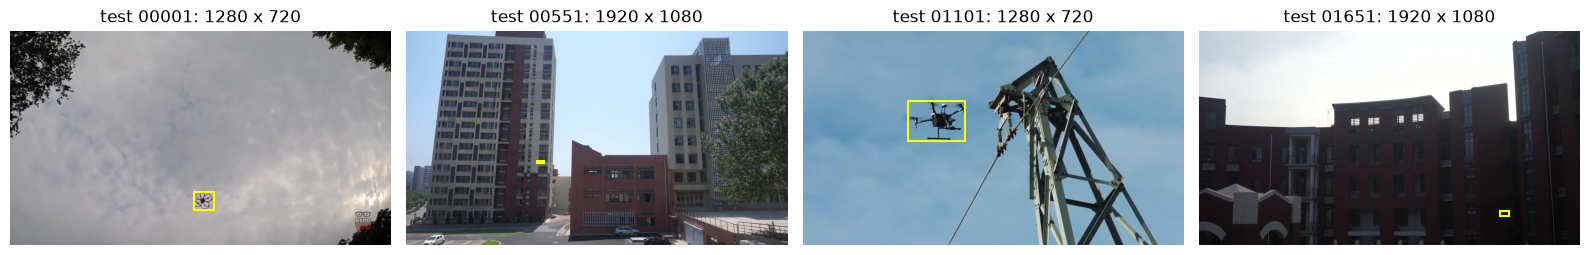

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, row in zip(axes, DETECTION["test"].select(range(0, 2200, 550))):
    ax.imshow(Image.open(io.BytesIO(row["image"]["bytes"])))
    for x1, y1, x2, y2 in row["objects"]["bbox"]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="yellow", lw=1.5))
    ax.set_title(f"test {row['image_id']}: {row['width']} x {row['height']}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fine-tuning the detector

You start from a detector pretrained on COCO, whose 80 classes do not include drones, and fine-tune it for the single `UAV` class. The pretrained backbone already encodes edges, textures and object parts, so a few thousand labeled images are enough to adapt the head and the upper layers. Use the nano-sized model of the YOLO11 family (`yolo11n.pt`, about 2.6 million parameters). It trains quickly and runs on every frame of the tracking videos in minutes.

Two settings matter for small targets. The input size sets how many pixels a drone covers after resizing, and the validation split decides which epoch's weights you keep. The training loop keeps the weights with the best validation score in `RUNS/detector/weights/best.pt`.

In [9]:
from ultralytics import YOLO

# TODO: fine-tune the detector. The stub below trains for only 3 epochs so that every later
#   cell runs quickly; its detector is the baseline you must beat. Replace it with your own
#   training run. Keep the output location: later cells load RUNS / "detector" / "weights" / "best.pt".
t0 = time.time()
model = YOLO("yolo11n.pt")
model.train(data=str(DATA_YAML), epochs=3, imgsz=IMGSZ, batch=16, workers=2,
            amp=AMP, seed=0, device=DEVICE, project=str(RUNS.resolve()), name="detector",
            exist_ok=True, plots=False, verbose=False)
print(f"training took {(time.time() - t0) / 60:.1f} min")

Ultralytics 8.4.189 🚀 Python-3.12.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA RTX A4000, 15984MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dut-data/dut.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=detector, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=False, pose=12.0, pretrained=

Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 92% ━━━━━━━━━━━─ 12/13 4.8it/s 6.4s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 1.2it/s 10.7s

                   all        400        406      0.845      0.591      0.674      0.326


Speed: 0.1ms preprocess, 21.2ms inference, 0.0ms loss, 2.2ms postprocess per image


training took 1.8 min


## Detection accuracy on the test split

Average precision at an IoU threshold of 0.5 (mAP@0.5) counts a detection as correct when its box overlaps a labeled drone by at least half of their union, ranks all detections by confidence, and integrates precision over recall. With one class, the mean over classes is just that class's average precision. The stricter mAP@0.5:0.95 averages the same quantity over IoU thresholds from 0.5 to 0.95. Evaluating at a larger input size than the training size often helps small objects, because the drone covers more pixels.

In [10]:
detector = YOLO(RUNS / "detector" / "weights" / "best.pt")
det_results = {}
for size in (IMGSZ, 1280):
    metrics = detector.val(data=str(DATA_YAML), split="test", imgsz=size, batch=16, device=DEVICE,
                           plots=False, verbose=False, project=str(RUNS.resolve()), name=f"test_{size}",
                           exist_ok=True)
    det_results[size] = (metrics.box.map50, metrics.box.map)
    print(f"test split, input {size}: mAP@0.5 = {metrics.box.map50:.3f}, mAP@0.5:0.95 = {metrics.box.map:.3f}")

Ultralytics 8.4.189 🚀 Python-3.12.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA RTX A4000, 15984MiB)


YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 166.3±11.2 MB/s, size: 231.5 KB)


val: Scanning /home/pantelis.monogioudis/scratch/dut-anti-uav/nbrun/dut-data/yolo/labels/test.cache... 2200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2200/2200 709.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 1/138 2.8s/it 0.8s<6:23

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 99% ━━━━━━━━━━━╸ 137/138 6.1it/s 27.6s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 138/138 5.0it/s 27.8s

                   all       2200       2245       0.78      0.676      0.746      0.392


Speed: 1.1ms preprocess, 5.7ms inference, 0.0ms loss, 1.9ms postprocess per image


test split, input 1280: mAP@0.5 = 0.746, mAP@0.5:0.95 = 0.392


## The tracking data

The tracking part of the benchmark has 20 videos, `video01` to `video20`, with 24,804 frames in total. Sequences run from 83 to 2,635 frames. Every frame comes with a ground-truth box `[x, y, w, h]`: the top-left corner, the width and the height of the drone's box in pixels. When the drone is out of view, the box reads `[-100, -100, -100, -100]`. That happens in 2,586 frames, all in 9 of the videos, and the loader below turns those boxes into `NaN`. The frames are written to disk once, one folder per video, with one ground-truth file per video holding one line per frame.

In [11]:
TRACK_ROOT = DATA / "track"
if not (TRACK_ROOT / "Anti-UAV-Tracking-V0GT").exists():
    tracking = load_dataset("aegean-ai/dut-anti-uav", "tracking", split="test")
    tracking = tracking.cast_column("image", ImageFeature(decode=False))  # keep raw JPEG bytes
    boxes = {}
    for row in tracking:  # rows are sorted by video, then frame
        frame_dir = TRACK_ROOT / "Anti-UAV-Tracking-V0" / row["video_id"]
        frame_dir.mkdir(parents=True, exist_ok=True)
        (frame_dir / f"{row['frame_index']:05d}.jpg").write_bytes(row["image"]["bytes"])
        boxes.setdefault(row["video_id"], []).append(row["bbox"])
    gt_dir = TRACK_ROOT / "Anti-UAV-Tracking-V0GT"
    gt_dir.mkdir()  # written last, so its presence marks a finished export
    for video_id, rows in boxes.items():
        np.savetxt(gt_dir / f"{video_id}_gt.txt", np.array(rows), fmt="%d")
SEQUENCES = [f"video{i:02d}" for i in range(1, 21)]

In [12]:
def load_sequence(track_root, name):
    """Frame paths, ground truth (N x 4, x y w h, NaN where the drone is absent), first box."""
    frames = sorted((Path(track_root) / "Anti-UAV-Tracking-V0" / name).glob("*.jpg"))
    gt = np.loadtxt(Path(track_root) / "Anti-UAV-Tracking-V0GT" / f"{name}_gt.txt", dtype=float)
    gt[(gt[:, 2] <= 0) | (gt[:, 3] <= 0)] = np.nan  # -100 -100 -100 -100 marks an absent target
    assert len(frames) == len(gt), (name, len(frames), len(gt))
    return frames, gt

In [13]:
GT = {name: load_sequence(TRACK_ROOT, name)[1] for name in SEQUENCES}
for name in SEQUENCES:
    gt = GT[name]
    visible = ~np.isnan(gt[:, 0])
    print(f"{name}: {len(gt):5d} frames, drone absent in {(~visible).sum():4d}, "
          f"median box {np.nanmedian(gt[:, 2]):.0f} x {np.nanmedian(gt[:, 3]):.0f} px")

video01:  1050 frames, drone absent in    0, median box 95 x 41 px
video02:    83 frames, drone absent in    0, median box 57 x 20 px
video03:   100 frames, drone absent in    0, median box 34 x 34 px
video04:   341 frames, drone absent in    0, median box 86 x 64 px
video05:   450 frames, drone absent in    0, median box 51 x 37 px
video06:   200 frames, drone absent in    0, median box 92 x 72 px
video07:  2480 frames, drone absent in  653, median box 148 x 57 px
video08:  2305 frames, drone absent in  233, median box 92 x 38 px
video09:  2500 frames, drone absent in  938, median box 115 x 50 px
video10:  2635 frames, drone absent in  328, median box 115 x 45 px
video11:  1000 frames, drone absent in    2, median box 158 x 84 px
video12:  1485 frames, drone absent in  147, median box 60 x 36 px
video13:  1915 frames, drone absent in    1, median box 53 x 30 px
video14:   590 frames, drone absent in    0, median box 71 x 41 px
video15:  1350 frames, drone absent in  245, median box 60

## Scoring a tracker

The one-pass evaluation starts the tracker from the ground-truth box in the first frame and lets it run to the end of the sequence without any reset. Two numbers summarize the result.

The success curve plots, for each overlap threshold $\tau$ between 0 and 1, the fraction of frames whose predicted box $B_t$ overlaps the ground truth $G_t$ by more than $\tau$:

$$
\mathrm{IoU}_t = \frac{|B_t \cap G_t|}{|B_t \cup G_t|}, \qquad S(\tau) = \frac{1}{T}\sum_{t=1}^{T} \mathbb{1}\left[\mathrm{IoU}_t > \tau\right].
$$

Its area under the curve (AUC), computed as the mean of $S(\tau)$ over 21 evenly spaced thresholds, is the headline score. The precision curve does the same with the distance between box centers and reports the fraction of frames whose center error is at most 20 pixels.

Frames in which the drone is absent have no ground-truth box, so they are left out of both curves. A frame in which the method reports no box scores an IoU of 0 and an infinite center error. Both curves are computed per sequence and then averaged over the 20 sequences, so a short sequence counts as much as a long one. A separate number, the absent-box rate, measures how often a method still reports a box when the drone is out of view.

In [14]:
def iou_xywh(a, b):
    """IoU of matching rows of two N x 4 arrays of x y w h boxes. NaN rows give IoU 0."""
    ax2, ay2 = a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx2, by2 = b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2, bx2) - np.maximum(a[:, 0], b[:, 0]), 0, None)
    ih = np.clip(np.minimum(ay2, by2) - np.maximum(a[:, 1], b[:, 1]), 0, None)
    inter = iw * ih
    union = a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter
    iou = inter / np.where(union > 0, union, 1)
    return np.nan_to_num(iou, nan=0.0)


def center_error(a, b):
    """Euclidean distance between box centers in pixels. NaN predictions give infinity."""
    ca = a[:, :2] + a[:, 2:] / 2
    cb = b[:, :2] + b[:, 2:] / 2
    err = np.linalg.norm(ca - cb, axis=1)
    return np.where(np.isnan(err), np.inf, err)


IOU_THRESHOLDS = np.linspace(0, 1, 21)
PIXEL_THRESHOLDS = np.arange(0, 51)


def evaluate_sequence(pred, gt):
    """One-pass evaluation of one sequence on the frames where the drone is visible.

    pred and gt are N x 4 arrays of x y w h boxes. A NaN row in pred means the method
    reported no box in that frame and scores IoU 0 and infinite center error.
    Returns the success curve over IOU_THRESHOLDS and the precision curve over
    PIXEL_THRESHOLDS.
    """
    visible = ~np.isnan(gt[:, 0])
    iou = iou_xywh(pred[visible], gt[visible])
    err = center_error(pred[visible], gt[visible])
    success = np.array([(iou > t).mean() for t in IOU_THRESHOLDS])
    precision = np.array([(err <= t).mean() for t in PIXEL_THRESHOLDS])
    return success, precision


def evaluate_all(preds, gts):
    """Average per-sequence curves. Returns success AUC, precision at 20 px, and the curves."""
    curves = [evaluate_sequence(preds[k], gts[k]) for k in gts]
    success = np.mean([c[0] for c in curves], axis=0)
    precision = np.mean([c[1] for c in curves], axis=0)
    return {"auc": float(success.mean()), "p20": float(precision[20]),
            "success": success, "precision": precision}


def absent_box_rate(pred, gt):
    """Fraction of frames with no drone in which the method still reports a box."""
    absent = np.isnan(gt[:, 0])
    if not absent.any():
        return np.nan
    return float((~np.isnan(pred[absent, 0])).mean())

## Detections on every frame

The tracker consumes the detector's output one frame at a time. Running the detector is the slow step, so it runs once over all 24,804 frames and the boxes are saved: up to 10 boxes per frame with confidence of at least 0.01, each stored as `x1 y1 x2 y2 confidence`. The low floor keeps weak detections so that the tracker, not the detector, decides which ones to trust. The file is named after the detector's weights, so a retrained detector never reuses old boxes.

In [15]:
import hashlib

WEIGHTS = RUNS / "detector" / "weights" / "best.pt"
CACHE = DATA / f"detections_{TRACK_IMGSZ}_{hashlib.md5(WEIGHTS.read_bytes()).hexdigest()[:8]}.pkl"
if CACHE.exists():
    DETS = pickle.loads(CACHE.read_bytes())
else:
    DETS, t0 = {}, time.time()
    for name in SEQUENCES:
        frames, _ = load_sequence(TRACK_ROOT, name)
        per_frame = []
        for i in range(0, len(frames), 16):
            for r in detector.predict([str(f) for f in frames[i:i + 16]], imgsz=TRACK_IMGSZ, conf=0.01,
                                      max_det=10, half=AMP, device=DEVICE, verbose=False):
                per_frame.append(np.hstack([r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()[:, None]]))
        DETS[name] = per_frame
        print(f"{name}: {len(frames)} frames, {time.time() - t0:.0f} s so far")
    CACHE.write_bytes(pickle.dumps(DETS))

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


...

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


video20: 1635 frames, 528 s so far


## The detector on its own

The simplest tracker reports, in every frame, the detector's most confident box, and reports nothing when no box clears a confidence threshold. It has no memory. A missed detection becomes a lost frame, and a confident false positive anywhere in the image becomes the track. The first frame is set to the ground truth, exactly as the Kalman tracker will be, so the two methods start from the same place.

In [16]:
def best_box_per_frame(dets, min_conf):
    """Highest-confidence detection in each frame, as x y w h; NaN when none passes min_conf.

    dets is a list with one (K x 5) array per frame: x1 y1 x2 y2 conf.
    """
    out = np.full((len(dets), 4), np.nan)
    for i, d in enumerate(dets):
        d = d[d[:, 4] >= min_conf]
        if len(d):
            x1, y1, x2, y2, _ = d[np.argmax(d[:, 4])]
            out[i] = [x1, y1, x2 - x1, y2 - y1]
    return out

In [17]:
def detector_only(min_conf):
    preds = {}
    for name in SEQUENCES:
        p = best_box_per_frame(DETS[name], min_conf)
        p[0] = GT[name][0]
        preds[name] = p
    return preds


def summary(preds):
    r = evaluate_all(preds, GT)
    r["absent"] = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in SEQUENCES])
    return r


for th in (0.01, 0.05, 0.1, 0.25, 0.5):
    r = summary(detector_only(th))
    print(f"min confidence {th:4.2f}: success AUC {r['auc']:.3f}, precision@20px {r['p20']:.3f}, "
          f"absent-box rate {r['absent']:.2f}")

min confidence 0.01: success AUC 0.577, precision@20px 0.776, absent-box rate 0.78


min confidence 0.05: success AUC 0.565, precision@20px 0.756, absent-box rate 0.58


min confidence 0.10: success AUC 0.554, precision@20px 0.738, absent-box rate 0.41


min confidence 0.25: success AUC 0.534, precision@20px 0.707, absent-box rate 0.26


min confidence 0.50: success AUC 0.501, precision@20px 0.658, absent-box rate 0.13


## A Kalman filter for one drone

The filter tracks the box center, the velocity of the center, and the box size, so its state is

$$
\mathbf{x} = \begin{bmatrix} c_x & c_y & v_x & v_y & w & h \end{bmatrix}^\top .
$$

A detection gives the measurement $\mathbf{z} = [c_x, c_y, w, h]^\top$. It observes the center and the size but not the velocity. The center moves with constant velocity, one step per frame, and the width and height follow a random walk. From this description you derive the transition matrix $F$, the measurement matrix $H$, the process noise $Q$ and the measurement noise $R$.

Not every detection comes from the drone. Before each update the filter compares the detections with its prediction and rejects those that lie too far from it. Measure that distance with the squared Mahalanobis distance of the innovation, and set the threshold from the distribution that distance follows when the detection is correct. When no detection passes, the filter skips the update and coasts on its prediction. You decide how long a track may coast before it is declared lost, and how a new track starts after that.

In [18]:
from filterpy.kalman import KalmanFilter

In [19]:
def xyxy_to_z(box):
    """[x1, y1, x2, y2] to the measurement [cx, cy, w, h]."""
    x1, y1, x2, y2 = box[:4]
    return np.array([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1])


def z_to_xywh(z):
    """[cx, cy, w, h] to the evaluation format [x, y, w, h] (top-left corner)."""
    cx, cy, w, h = z
    return np.array([cx - w / 2, cy - h / 2, w, h])

In [20]:
class DroneTracker:
    """Kalman tracker for a single drone.

    State x = [cx, cy, vx, vy, w, h]; measurement z = [cx, cy, w, h]; one step = one frame.
    accel_std and meas_std are the process and measurement noise settings swept later on.
    """

    def __init__(self, accel_std=1.0, meas_std=1.0):
        self.accel_std = accel_std
        self.meas_std = meas_std
        # TODO: add the other settings your tracker needs, with the values you chose.

    def start(self, z):
        """Start a track at measurement z = [cx, cy, w, h]."""
        # TODO: create a filterpy KalmanFilter for this track.

    def step(self, dets):
        """Advance one frame. dets is a (K x 5) array x1 y1 x2 y2 conf.

        Returns the estimate as [x, y, w, h], or NaNs when there is no track.
        """
        # TODO: the tracker. Predict, gate the detections, update, and handle missed
        #   detections, track loss and starting a new track.
        # Stub: report the most confident detection with no filtering (the detector alone).
        if len(dets):
            return z_to_xywh(xyxy_to_z(dets[np.argmax(dets[:, 4])]))
        return np.full(4, np.nan)

In [21]:
def run_tracker(dets, first_box, **params):
    """Track one sequence. first_box is the ground truth x y w h of frame 1 (one-pass protocol)."""
    tracker = DroneTracker(**params)
    x, y, w, h = first_box
    tracker.start(np.array([x + w / 2, y + h / 2, w, h]))
    out = [np.array(first_box, dtype=float)]
    for d in dets[1:]:
        out.append(tracker.step(d))
    return np.array(out)

## Tracking all 20 sequences

Choose the settings of `DroneTracker` on the odd-numbered sequences only, and use the even-numbered ones to check that you did not fit them to the videos you score on. The table reports the detector alone, at the confidence threshold that scores best on the odd sequences, next to the Kalman tracker. Until you implement the filter, the tracker's stub reports the detector's most confident box, so its row matches the detector alone. Once the filter runs, compare the two rows column by column and explain what you see.

In [22]:
ODD = [k for k in SEQUENCES if int(k[-2:]) % 2 == 1]
EVEN = [k for k in SEQUENCES if int(k[-2:]) % 2 == 0]


def score(preds, keys):
    r = evaluate_all({k: preds[k] for k in keys}, {k: GT[k] for k in keys})
    absent = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in keys])
    return r["auc"], r["p20"], absent


best_th = max((0.01, 0.05, 0.1, 0.25, 0.5), key=lambda th: score(detector_only(th), ODD)[0])
DET_PREDS = detector_only(best_th)
t0 = time.time()
KF_PREDS = {name: run_tracker(DETS[name], GT[name][0]) for name in SEQUENCES}
print(f"Kalman tracking of {sum(len(g) for g in GT.values())} frames took {time.time() - t0:.1f} s")
print(f"{'method':32s} {'subset':6s} {'AUC':>6s} {'P@20':>6s} {'absent':>7s}")
for label, preds in ((f"detector alone (conf >= {best_th})", DET_PREDS), ("detector + Kalman filter", KF_PREDS)):
    for subset, keys in (("odd", ODD), ("even", EVEN), ("all", SEQUENCES)):
        auc, p20, absent = score(preds, keys)
        print(f"{label:32s} {subset:6s} {auc:6.3f} {p20:6.3f} {absent:7.2f}")

Kalman tracking of 24804 frames took 0.2 s
method                           subset    AUC   P@20  absent
detector alone (conf >= 0.01)    odd     0.561  0.748    0.82
detector alone (conf >= 0.01)    even    0.593  0.803    0.72
detector alone (conf >= 0.01)    all     0.577  0.776    0.78
detector + Kalman filter         odd     0.561  0.748    0.82
detector + Kalman filter         even    0.593  0.803    0.72
detector + Kalman filter         all     0.577  0.776    0.78


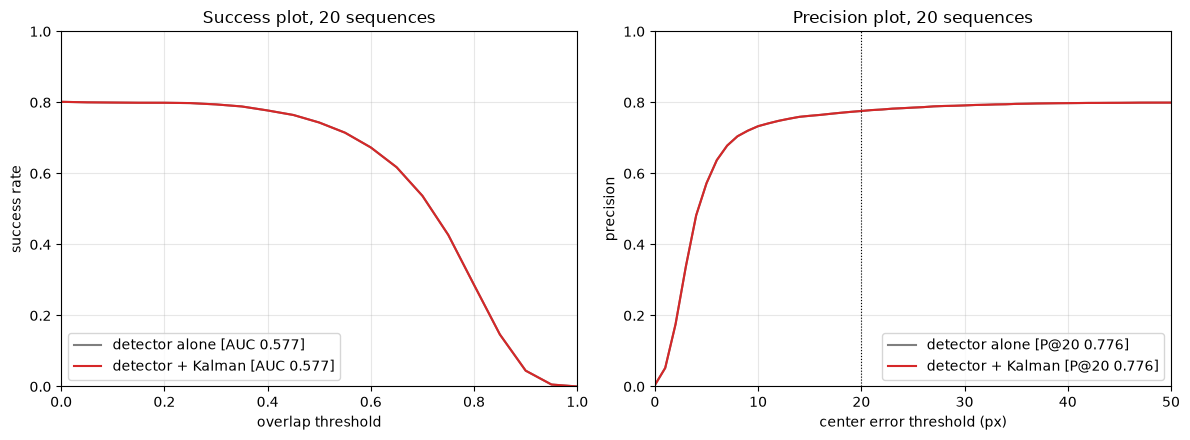

In [23]:
det_all, kf_all = evaluate_all(DET_PREDS, GT), evaluate_all(KF_PREDS, GT)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
for r, label, color in ((det_all, "detector alone", "tab:gray"), (kf_all, "detector + Kalman", "tab:red")):
    a1.plot(IOU_THRESHOLDS, r["success"], color=color, label=f"{label} [AUC {r['auc']:.3f}]")
    a2.plot(PIXEL_THRESHOLDS, r["precision"], color=color, label=f"{label} [P@20 {r['p20']:.3f}]")
a1.set(xlabel="overlap threshold", ylabel="success rate", title="Success plot, 20 sequences", xlim=(0, 1), ylim=(0, 1))
a2.set(xlabel="center error threshold (px)", ylabel="precision", title="Precision plot, 20 sequences", xlim=(0, 50), ylim=(0, 1))
a2.axvline(20, color="k", lw=0.8, ls=":")
for a in (a1, a2):
    a.grid(alpha=0.3)
    a.legend(loc="lower left" if a is a1 else "lower right")
plt.tight_layout()
plt.show()

In [24]:
rows = []
for name in SEQUENCES:
    d_auc, _, _ = score(DET_PREDS, [name])
    k_auc, _, _ = score(KF_PREDS, [name])
    rows.append((name, d_auc, k_auc))
print(f"{'sequence':9s} {'frames':>6s} {'absent':>6s} {'det AUC':>8s} {'KF AUC':>7s} {'change':>7s}")
for name, d_auc, k_auc in rows:
    gt = GT[name]
    print(f"{name:9s} {len(gt):6d} {int(np.isnan(gt[:, 0]).sum()):6d} {d_auc:8.3f} {k_auc:7.3f} {k_auc - d_auc:+7.3f}")

sequence  frames absent  det AUC  KF AUC  change
video01     1050      0    0.636   0.636  +0.000
video02       83      0    0.692   0.692  +0.000
video03      100      0    0.773   0.773  +0.000
video04      341      0    0.635   0.635  +0.000
video05      450      0    0.715   0.715  +0.000
video06      200      0    0.806   0.806  +0.000
video07     2480    653    0.718   0.718  +0.000
video08     2305    233    0.783   0.783  +0.000
video09     2500    938    0.816   0.816  +0.000
video10     2635    328    0.688   0.688  +0.000
video11     1000      2    0.778   0.778  +0.000
video12     1485    147    0.439   0.439  +0.000
video13     1915      1    0.088   0.088  +0.000
video14      590      0    0.452   0.452  +0.000
video15     1350    245    0.380   0.380  +0.000
video16     1285      0    0.196   0.196  +0.000
video17      780      0    0.186   0.186  +0.000
video18     1320     39    0.707   0.707  +0.000
video19     1300      0    0.518   0.518  +0.000
video20     1635    

/tmp/ipykernel_1469866/1150791356.py:7: RuntimeWarning: Mean of empty slice
  absent = np.nanmean([absent_box_rate(preds[k], GT[k]) for k in keys])


## The track drawn on the video

The output video for one sequence shows the ground-truth box in green, the Kalman estimate in red, and the estimated center's path as a red polyline. The path breaks where the track was lost. Frames with no drone in view have no green box.

In [25]:
VIDEO_NAME = "video12"  # change this to look at another sequence


def render(name, preds, out_path, scale=0.5, fps=25):
    frames, gt = load_sequence(TRACK_ROOT, name)
    writer, path = None, []
    for i, frame_path in enumerate(frames):
        image = cv2.imread(str(frame_path))
        image = cv2.resize(image, None, fx=scale, fy=scale)
        if writer is None:
            h, w = image.shape[:2]
            writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))
        g, p = gt[i] * scale, preds[i] * scale
        if not np.isnan(g[0]):
            cv2.rectangle(image, (int(g[0]), int(g[1])), (int(g[0] + g[2]), int(g[1] + g[3])), (0, 200, 0), 1)
        if np.isnan(p[0]):
            path.append(None)
        else:
            cv2.rectangle(image, (int(p[0]), int(p[1])), (int(p[0] + p[2]), int(p[1] + p[3])), (0, 0, 255), 2)
            path.append((int(p[0] + p[2] / 2), int(p[1] + p[3] / 2)))
        for a, b in zip(path[:-1], path[1:]):
            if a is not None and b is not None:
                cv2.line(image, a, b, (0, 0, 255), 1)
        cv2.putText(image, f"{name} frame {i + 1}", (10, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)
        writer.write(image)
    writer.release()
    return out_path


video_path = render(VIDEO_NAME, KF_PREDS[VIDEO_NAME], Path(f"{VIDEO_NAME}_kalman.mp4"))
print("wrote", video_path)

wrote video12_kalman.mp4


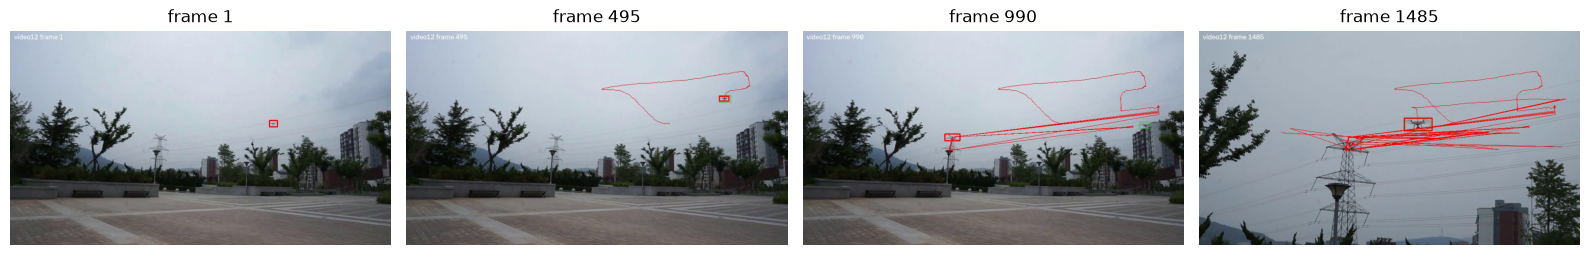

In [26]:
capture = cv2.VideoCapture(str(video_path))
count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
fig, axes = plt.subplots(1, 4, figsize=(16, 2.8))
for ax, index in zip(axes, np.linspace(0, count - 1, 4).astype(int)):
    capture.set(cv2.CAP_PROP_POS_FRAMES, index)
    ok, frame = capture.read()
    ax.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax.set_title(f"frame {index + 1}")
    ax.axis("off")
capture.release()
plt.tight_layout()
plt.show()

## Losing and reacquiring the drone

On a hard sequence, much of a tracker's score depends on how it finds the drone again after losing it. video13 is the hardest case in the benchmark. The drone is small and often hard to see, and the detector finds it in only part of the frames, many of them with low confidence. Long stretches pass with no detection on the drone at all.

A tracker that gives up after a run of missed frames, and then waits for a confident detection anywhere in the image, can stay silent through long stretches in which the detector does see the drone. On such a sequence it can score below the detector alone, even though it has the same detections and more information about where the drone was.

Your tracker has to handle this case. Decide when the track counts as lost, what the filter does while it is lost, and which detections may restart it. Change `DroneTracker` above, choose any new settings on the odd-numbered sequences as before, and rerun the cells from the tracking section down. Your final tracker must meet two conditions:

- On video13, its AUC is at least that of the detector alone.
- Over all 20 sequences, its absent-box rate stays below that of the detector alone.

The check below reports both. The plot after it shows, frame by frame, the overlap of each method's box with the ground truth. A red band marks frames in which the method reports no box while the drone is in view, and a gray band marks frames with no drone in view.

In [27]:
d13, k13 = score(DET_PREDS, ["video13"]), score(KF_PREDS, ["video13"])
d_all, k_all = score(DET_PREDS, SEQUENCES), score(KF_PREDS, SEQUENCES)
print(f"video13 AUC: detector alone {d13[0]:.3f}, your tracker {k13[0]:.3f}")
print(f"absent-box rate on all 20 sequences: detector alone {d_all[2]:.2f}, your tracker {k_all[2]:.2f}")
met = k13[0] >= d13[0] and k_all[2] < d_all[2]
print("both conditions met" if met else "not met yet")

video13 AUC: detector alone 0.088, your tracker 0.088
absent-box rate on all 20 sequences: detector alone 0.78, your tracker 0.78
not met yet


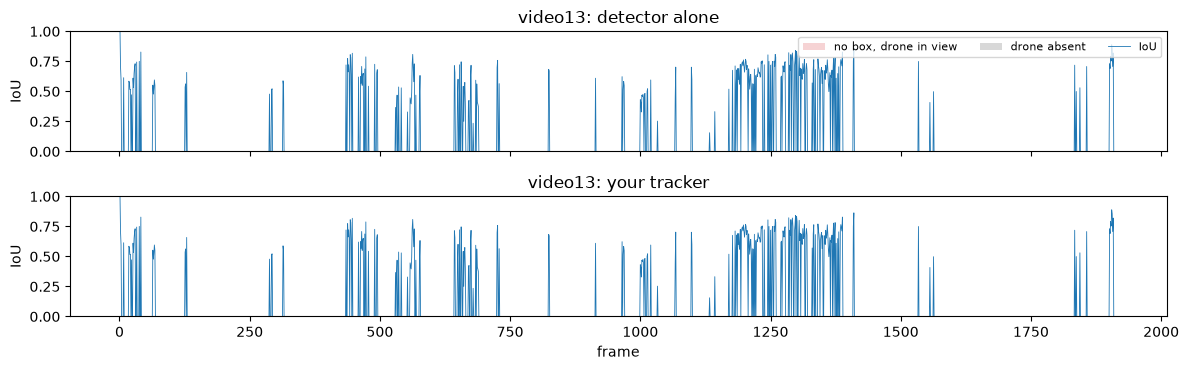

In [28]:
def plot_timeline(name, preds_by_label):
    """Per-frame IoU with the ground truth for each method on one sequence."""
    gt = GT[name]
    t = np.arange(1, len(gt) + 1)
    fig, axes = plt.subplots(len(preds_by_label), 1, figsize=(12, 1.9 * len(preds_by_label)), sharex=True,
                             squeeze=False)
    for ax, (label, pred) in zip(axes[:, 0], preds_by_label.items()):
        absent = np.isnan(gt[:, 0])
        nobox = np.isnan(pred[:, 0]) & ~absent
        ax.fill_between(t, 0, 1, where=nobox, color="tab:red", alpha=0.2, step="mid", lw=0,
                        label="no box, drone in view")
        ax.fill_between(t, 0, 1, where=absent, color="0.5", alpha=0.3, step="mid", lw=0, label="drone absent")
        ax.plot(t, iou_xywh(pred, gt), color="tab:blue", lw=0.6, label="IoU")
        ax.set(ylim=(0, 1), ylabel="IoU", title=f"{name}: {label}")
    axes[-1, 0].set_xlabel("frame")
    axes[0, 0].legend(loc="upper right", fontsize=8, ncol=3)
    plt.tight_layout()
    plt.show()


plot_timeline("video13", {"detector alone": DET_PREDS["video13"], "your tracker": KF_PREDS["video13"]})

## Noise sensitivity

The ratio of process noise to measurement noise sets how much the filter trusts its motion model over the detector. Sweep `accel_std` and `meas_std` over at least three values each, keeping the other settings at their defaults, and score each setting on all 20 sequences. Use the result in your answer to question 2.

In [29]:
# TODO: extend both lists to at least three values each.
ACCEL_GRID = [DroneTracker().accel_std]
MEAS_GRID = [DroneTracker().meas_std]
print(f"{'accel_std':>9s} {'meas_std':>8s} {'AUC':>6s} {'P@20':>6s}")
SWEEP = {}
for accel_std in ACCEL_GRID:
    for meas_std in MEAS_GRID:
        preds = {n: run_tracker(DETS[n], GT[n][0], accel_std=accel_std, meas_std=meas_std) for n in SEQUENCES}
        auc, p20, _ = score(preds, SEQUENCES)
        SWEEP[(accel_std, meas_std)] = (auc, p20)
        print(f"{accel_std:9.2f} {meas_std:8.2f} {auc:6.3f} {p20:6.3f}")

accel_std meas_std    AUC   P@20


     1.00     1.00  0.577  0.776


## Questions

Answer each question in the cell below it, in a few sentences, and support your answer with numbers from your own run.

**Question 1. State design.** The state models the center with constant velocity and the size with a random walk. Why is it reasonable to leave the size without a velocity term on these videos? Name one situation in the benchmark where a constant-velocity model on the center is wrong, and say what the filter does in that situation.

*Your answer here.*

**Question 2. Noise choices.** Use your sweep. What happens to the scores when `accel_std` is much smaller than `meas_std`, and when it is much larger? Explain each trend with the Kalman gain: which source does the filter trust in each case, and what kind of error does that produce on a fast-moving drone and on a jittery detector?

*Your answer here.*

**Question 3. Gating and missed detections.** Compare the absent-box rates of the two methods and explain the difference. What do your coasting limit and the gate trade off when the drone leaves the frame or passes behind a tree?

*Your answer here.*

**Question 4. Failure cases.** Pick the sequence where the Kalman tracker scores lowest, or where it does worse than the detector alone. Render it with `render`, watch it, and describe what goes wrong and in which frames. Would a better motion model fix it, or does the problem sit in the detector?

*Your answer here.*

**Question 5. Where the numbers come from.** The 424 training and validation images that are frames of the tracking videos were held out of training. Other detection images may still come from the same sites as the tracking videos, filmed at another time. What does that mean for how far you would trust these tracking scores on video from a new site? Would it change the comparison between the detector alone and the detector with the filter, and why?

*Your answer here.*

**Question 6. Losing and reacquiring the track.** Describe how your tracker decides that the drone is lost, what the filter does while the track is lost, and which detections can restart it. Report the video13 AUC and the absent-box rate on all 20 sequences with and without your reacquisition rule, and show the video13 plot for both with `plot_timeline`. What does the rule cost on the other sequences?

*Your answer here.*